# scProto with the new loss on spatial — niche-program recovery (DGE)

**Question.** The plan1 rebuttal experiment found SEACells *ahead* of scProto on
niche-program recovery, and the diagnosis was that scProto's niche-positive metacells
were built from too few real cells to give a stable pseudobulk fold-change — i.e. the
over-merging / fragmentation failure (a few giant prototypes plus many near-singletons).
The corrected `nassoc` diagonal is meant to fix exactly that. So:

> Does the new loss remove the collapse, and does removing it close the DGE gap?

**Dataset: `ss28nsc` only** (NSCLC CosMx, one slide). One dataset, run fully, before any
second tissue — same rule as the rest of this project.

**What runs here**

| Step | Cost | Cached as |
|---|---|---|
| 1. train scProto, new loss (`nassoc_diag_norm='pair'`) | training | checkpoint under `MODEL_DIR/ss28nsc/` |
| 2. train scProto, old loss (`'volume'`), same everything else | training | ditto |
| 3. collapse diagnostics on both | seconds | `tables/` |
| 4. ground-truth niche DE from real single cells | minutes | `files/celltype_niches_full.csv` |
| 5. DGE recovery per arm | minutes | `tables/ss28nsc/<arm>_per_pair.csv` |
| 6. comparison + size-floor sweep + figures | seconds | `tables/`, `figures/` |

**Resuming after a Colab disconnect.** Every step is load-if-exists. Re-run the notebook
top to bottom: finished steps print `loaded from ...` and cost nothing. Set
`LOAD_UMAP = True` to reload trained checkpoints instead of retraining, and
`FORCE_RERUN = True` only to deliberately recompute the eval tables.

**Read before running.** `bk08` (BANKSY, lambda=0.8) needs `X_bk08` precomputed on the
**full tissue**. If `ss28nsc` is a filtered subset and `X_bk08` is not already in
`adata.obsm`, the affinity code will compute it on the subset, where the neighbour-mean
term sees only the surviving cells — that is not the real spatial context. The affinity
cell prints a warning if this happens; do not report numbers from a run that warned.

## Setup

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# Multi-pass on purpose — collapsing this to one pin has been tried and fails.
# statsmodels: branch 2's weighted t-test. diptest: the collapse dip test.
# SEACells always --no-deps (prot_init='waypoint' needs its diffusion-map code).
!pip install -q scarches faiss-gpu-cu12 scib-metrics
!pip install git+https://github.com/dpeerlab/SEACells.git --quiet --no-deps
!pip install numpy scipy --upgrade -q
!pip install -q palantir harmonypy
!pip install -q "numpy==1.26.4" "scipy==1.13.1"
!pip install --upgrade --force-reinstall numpy cupy-cuda12x
!pip install "numpy<2.3"
!pip install -q statsmodels diptest pybanksy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 8.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.2/130.2 kB 14.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.4/48.4 MB 55.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.0/42.0 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 187.5/187.5 kB 18.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 138.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.9/10.9 MB 151.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 99.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 711.2/711.2 kB 54.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.3/102.3 kB 12.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 118.2 MB/s eta 0:00:00
   ━━

  Using cached numpy-2.2.6-cp313-cp313-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (62 kB)
Using cached numpy-2.2.6-cp313-cp313-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (16.5 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 2.5.2
    Uninstalling numpy-2.5.2:
      Successfully uninstalled numpy-2.5.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
seacells 0.3.3 requires pyranges, which is not installed.
anndata 0.13.2 requires scipy!=1.17.0,>=1.14, but you have scipy 1.13.1 which is incompatible.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.5 which is incompatible.
giddy 2.3.9 requires scipy>=1.14, but you have scipy 1.13.1 which is incompatible.
tsfresh 0.21.2 requires scipy>=1.14.0; python_version >= "3.10", but you have scipy 1.13.1 which is incompatible.
xarray-einstats 0.11.0 requires scipy>

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 238.1/238.1 kB 19.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 83.3/83.3 kB 9.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
seacells 0.3.3 requires pyranges, which is not installed.


**RESTART THE RUNTIME NOW** (Runtime -> Restart session) before running anything below.
numpy/scipy/anndata are C-extension linked, so an in-process upgrade will not take
effect on already-imported modules. Skipping this is the exact cause of
`cannot import name '_center' from numpy._core.umath` on the next cell.

In [1]:
_checks = {
    "numpy": "numpy", "scipy": "scipy", "anndata": "anndata", "scanpy": "scanpy",
    "scarches": "scarches", "scvi-tools": "scvi", "seacells": "SEACells",
    "palantir": "palantir", "scib-metrics": "scib_metrics",
    "statsmodels": "statsmodels", "diptest": "diptest", "faiss": "faiss",
}
_failed = []
for pkg, mod in _checks.items():
    try:
        __import__(mod)
    except ImportError as e:
        _failed.append((pkg, str(e)))
if _failed:
    print("FAILED imports (fix, then restart the runtime again):")
    for pkg, err in _failed:
        print(f"  {pkg}: {err}")
else:
    print("All packages import cleanly.")

FAILED imports (fix, then restart the runtime again):
  scarches: cannot import name 'read' from 'anndata' (/usr/local/lib/python3.13/dist-packages/anndata/__init__.py)


In [2]:
%run /content/drive/MyDrive/codes/interpretable-prototype/notebooks/nb_setup.py

nb_setup done. Available: get_trainer, run_mc_task, fig_*, LAMBDA_PROTO_UMAP, LAMBDA_PROTO_UMAP_PRECON, LAMBDA_PARAM_UMAP, LAMBDA_RECON_ONLY, train_sure, eval_sure_task1/2/3
Configs: {'LAMBDA_PROTO_UMAP': {'lambda_umap': 1, 'lambda_swav': 0, 'lambda_kl': 0, 'lambda_recon': 0, 'lambda_proto_recon': 0.0, 'umap_similarity': 'proto'}, 'LAMBDA_PARAM_UMAP': {'lambda_umap': 1, 'lambda_swav': 0, 'lambda_kl': 0, 'lambda_recon': 0, 'lambda_proto_recon': 0.0, 'umap_similarity': 'embedding'}, 'LAMBDA_RECON_ONLY': {'lambda_umap': 0, 'lambda_swav': 0, 'lambda_kl': 0, 'lambda_recon': 1, 'lambda_proto_recon': 0.0}}


In [3]:
import os
import gc
import numpy as np
import pandas as pd
import scanpy as sc
import torch
import matplotlib.pyplot as plt

from interpretable_ssl.datasets.dataset_configs import DATASETS
from interpretable_ssl.evaluation.spatial_immune_task import NSCLC_EVAL_GROUPS
from interpretable_ssl.evaluation import niche_dge as nd
from interpretable_ssl.evaluation import collapse_diagnostics as cd

## Config

The two training arms differ in **one** setting, `nassoc_diag_norm`, so any difference
between them is attributable to the loss and nothing else.

```
'volume'  edges_inside / volume          old. volume is additive under merging, so
                                         merging two prototypes always raises the score
                                         -> hierarchical splits are penalized -> over-merging
'pair'    edges_inside / possible_pairs  new. the induced-subgraph edge density; pairs is
                                         superadditive, so merging LOWERS it -> the loss
                                         can finally rank a justified split above a merge
```

In [4]:
DS_ID = 'ss28nsc'
CT_KEY = 'celltypes'
NICHE_KEY = 'niches_2D'
AFFINITY = 'bk08'          # BANKSY lambda=0.8 + real SEACells RBF

NB_DIR = os.path.join(os.environ['CODE_DIR'], 'notebooks', 'spatial_new_loss_dge')
TABLE_DIR = os.path.join(NB_DIR, 'tables', DS_ID)
FIG_DIR = os.path.join(NB_DIR, 'figures')
GT_PATH = os.path.join(os.environ['CODE_DIR'], 'files', 'celltype_niches_full.csv')
POOLED_PATH = os.path.join(os.environ['CODE_DIR'], 'files', 'celltype_pooled_de.csv')
os.makedirs(TABLE_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

FORCE_RERUN = False        # True only to deliberately recompute the eval tables
LOAD_UMAP = False          # True on a re-run: reload trained checkpoints, skip training

# Epochs follow the project minimum. Both arms use identical values, so the loss
# comparison is not confounded by training length.
COMMON_KWARGS = dict(
    cvae_epochs=50,
    train_epochs=20,
    eval_freq=2,
    patience=4,
    batch_size=1024,
    umap_steps_per_epoch=500,
    niche_key=NICHE_KEY,
    target_groups=NSCLC_EVAL_GROUPS,
)
BASE_LAMBDA = LAMBDA_PROTO_UMAP_PRECON | {'nassoc_agg': 'max'}

NEW_LOSS = 'scProto (new loss, pair)'
OLD_LOSS = 'scProto (old loss, volume)'

trainers, labels = {}, {}

In [5]:
ds_conf = DATASETS[DS_ID]
adata = sc.read_h5ad(ds_conf['path'])
print(adata)
print('\ncell types:\n', adata.obs[CT_KEY].value_counts())
print('\nniches:\n', adata.obs[NICHE_KEY].value_counts(dropna=False))
print('\nX_bk08 precomputed:', 'X_bk08' in adata.obsm)

AnnData object with n_obs × n_vars = 28804 × 960
    obs: 'section', 'celltypes', 'niches_3D', 'niches_2D', 'fibroblast_subclusters', 'tumor_pseudotime_rank', 'EMT_niche'
    uns: 'EMT_niche_colors', 'celltypes_colors', 'fibroblast_subclusters_colors', 'log1p', 'neighbors', 'niches_2D_colors', 'niches_3D_colors', 'pca', 'umap'
    obsm: 'X_ctx', 'X_pca', 'X_umap', 'X_umap_2D_neighbourhoods', 'X_umap_3D_neighbourhoods', 'X_umap_SCT', 'spatial'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'
    layers: 'SCT', 'counts', None (.X)

cell types:
 celltypes
Fibroblasts                    7592
Tumor cells                    5650
Macrophages                    4590
Cytotoxic T cells              2931
Respiratory epithelium         1152
Vascular endothelium           1002
Monocytes                       922
Plasma cells                    821
Pericytes                       737
Smooth muscle cells             627
Regulatory T cells              548
Cycling immune cells            528
De

## 1. Train — new loss

One cell per arm so a disconnect costs one training run, not both.

In [ ]:
t, res, _ = run_mc_task(
    DS_ID, affinity_type=AFFINITY, load_umap=LOAD_UMAP,
    lambda_config=BASE_LAMBDA | {'nassoc_diag_norm': 'pair'},
    **COMMON_KWARGS,
)
trainers[NEW_LOSS] = t
labels[NEW_LOSS] = nd.labels_from_trainer(t)
print(t.get_model_name())
print(res)

 captum (see https://github.com/pytorch/captum).


dataset is None, loading ss28nsc
loading ss28nsc data
⚠️ No HVG column found.
proto_umap_ds-ss28_prtInit-wayp_aff-bk08_lprec0.01_usim-prot_cvae_e50_ecal1_lpu0.1_pum-ema_lna1_nagg-max_nadn-pair_upm-dotp_v31
Embedding dictionary:
 	Num conditions: [1]
 	Embedding dim: [10]
Encoder Architecture:
	Input Layer in, out and cond: 960 31 10
	Mean/Var Layer in/out: 31 8
Decoder Architecture:
	First Layer in, out and cond:  8 31 10
	Output Layer in/out:  31 960 

[16443] Generating affinities..., saving data to: ./graphs/affinity_ss28nsc28804_ncomp50_kneighbors50_bk08.pkl_tmp.h5ad
[graph_generator pid=17345] bk08
[graph_generator pid=17345] bk08: pybanksy (exact package), lambda=0.8, num_neighbours=32, n_components=50, then REAL SEACells build_graph.rbf (k=50) on top
[graph_generator pid=17345] [bk08] WARNING: X_bk08 not in adata.obsm -- computing it fresh HERE, on the 28804 cells currently in `ad`. If `ad` is already filtered to one cell type, the neighbour-mean term will only see same-type nei

waypoint MaxMin: 100%|██████████| 299/299 [00:00<00:00, 675.41proto/s]


[waypoint init] selected 300 seed cells


  0%|          | 0/1 [00:00<?, ?it/s]

...

  0%|          | 0/29 [00:00<?, ?it/s]

  0%|          | 0/29 [00:00<?, ?it/s]

UMAP data saved to /content/drive/MyDrive/models//ss28nsc/proto_umap_ds-ss28_prtInit-wayp_aff-bk08_lprec0.01_usim-prot_cvae_e50_ecal1_lpu0.1_pum-ema_lna1_nagg-max_nadn-pair_upm-dotp_v31


  0%|          | 0/29 [00:00<?, ?it/s]

proto_umap_ds-ss28_prtInit-wayp_aff-bk08_lprec0.01_usim-prot_cvae_e50_ecal1_lpu0.1_pum-ema_lna1_nagg-max_nadn-pair_upm-dotp_v31
{'seed': 31, 'purity': 0.6423739463425878, 'niche_purity': 0.5179941547352752, 'batch_entropy': -1.000000082690371e-10, 'modularity': 0.1716095243574171, 'coverage': 0.6111111111111112, 'dge_rbo_avg': 0.01007535101214743, 'dge_kendall_avg': 0.06100162467439355, 'dge_jaccard_avg': 0.012942974279482588, 'scgraph_corr_avg': 0.5830108599254802, 'scgraph_corr_std': 0.16775093650706224, 'ct_niche_rbo_avg': 0.002646340337653407, 'aff_compactness_per_batch': {'section_28': 1.0736528426744352}, 'aff_compactness_mean': 1.1807547164326404, 'tumor_cells_tumor_surface_purity': 0.23212108756371524, 'tumor_cells_tumor_surface_coverage': 0.9663685152057245, 'tumor_cells_tumor_surface_homogeneity': 0.6307692307692307, 'tumor_cells_tumor_core_purity': 0.1683855659418287, 'tumor_cells_tumor_core_coverage': 0.004872766648619383, 'tumor_cells_tumor_core_homogeneity': 0.58527341635

## 2. Train — old loss (the control)

In [ ]:
t, res, _ = run_mc_task(
    DS_ID, affinity_type=AFFINITY, load_umap=LOAD_UMAP,
    lambda_config=BASE_LAMBDA | {'nassoc_diag_norm': 'volume'},
    **COMMON_KWARGS,
)
trainers[OLD_LOSS] = t
labels[OLD_LOSS] = nd.labels_from_trainer(t)
print(t.get_model_name())
print(res)

dataset is None, loading ss28nsc
loading ss28nsc data
⚠️ No HVG column found.
proto_umap_ds-ss28_prtInit-wayp_aff-bk08_lprec0.01_usim-prot_cvae_e50_ecal1_lpu0.1_pum-ema_lna1_nagg-max_upm-dotp_v31
Embedding dictionary:
 	Num conditions: [1]
 	Embedding dim: [10]
Encoder Architecture:
	Input Layer in, out and cond: 960 31 10
	Mean/Var Layer in/out: 31 8
Decoder Architecture:
	First Layer in, out and cond:  8 31 10
	Output Layer in/out:  31 960 

📊 Affinity: wdeg[min/mean/max]=10.221/24.763/101.650, effk_med=57.8, mutual=100.00%
adam
Loaded pretrain checkpoint from /content/drive/MyDrive/models/ss28nsc/pretrain/pretrain_ds-ss28nsc_cvae_e50/pretrain_checkpoint.pth
  pretrain_params: {'dataset_id': 'ss28nsc', 'cvae_epochs': 50, 'batch_size': 1024, 'latent_dims': 8, 'l2norm': 1, 'model_type': 'gm', 'beta': 0.3, 'condition_key': 'section'}
[waypoint init] N=28804  K=300  n_eigs=10  nnz=1942916  nnz/row=67.5  w[min/mean/max]=4.472e-03/3.671e-01/9.886e-01  deg[min/mean/max]=10.22/24.76/101.65
[

waypoint MaxMin: 100%|██████████| 299/299 [00:00<00:00, 638.78proto/s]


[waypoint init] selected 300 seed cells


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/29 [00:00<?, ?it/s]

...

  0%|          | 0/29 [00:00<?, ?it/s]

  0%|          | 0/29 [00:00<?, ?it/s]

UMAP data saved to /content/drive/MyDrive/models//ss28nsc/proto_umap_ds-ss28_prtInit-wayp_aff-bk08_lprec0.01_usim-prot_cvae_e50_ecal1_lpu0.1_pum-ema_lna1_nagg-max_upm-dotp_v31


  0%|          | 0/29 [00:00<?, ?it/s]

proto_umap_ds-ss28_prtInit-wayp_aff-bk08_lprec0.01_usim-prot_cvae_e50_ecal1_lpu0.1_pum-ema_lna1_nagg-max_upm-dotp_v31
{'seed': 31, 'purity': 0.8159932540275591, 'niche_purity': 0.7952375473256778, 'batch_entropy': -1.000000082690371e-10, 'modularity': 0.5153787685131903, 'coverage': 0.8333333333333334, 'dge_rbo_avg': 0.1080858687378188, 'dge_kendall_avg': 0.15791027163771285, 'dge_jaccard_avg': 0.11118031562437837, 'scgraph_corr_avg': 0.6052755289224457, 'scgraph_corr_std': 0.16238008084932656, 'ct_niche_rbo_avg': 0.024972783991785107, 'aff_compactness_per_batch': {'section_28': 0.31781355275890366}, 'aff_compactness_mean': 0.3136796582396873, 'tumor_cells_tumor_surface_purity': 0.4040791688836048, 'tumor_cells_tumor_surface_coverage': 0.726654740608229, 'tumor_cells_tumor_surface_homogeneity': 0.7159212880143113, 'tumor_cells_tumor_core_purity': 0.3490240804547308, 'tumor_cells_tumor_core_coverage': 0.0969139144558744, 'tumor_cells_tumor_core_homogeneity': 0.7991337303735788, 'macroph

## 3. Baselines — load only, never retrain

`seacell` is SEACells on PCA: zero spatial signal, the transcriptomics-only baseline.
The pinned keyword is the exact scProto run the rebuttal's plan1 numbers came from
(`aff-ctx`, old loss), kept so the new numbers sit next to the ones already reported.
Any arm whose files are missing is dropped with a message rather than failing the cell.

In [ ]:
BASELINES = {
    'SEACells (PCA)': 'seacell',
    'scProto (plan1 run, ctx)': (
        'proto_umap_prtInit-wayp_aff-ctx_lprec0.01_usim-prot_ecal1'
        '_lpu0.1_pum-ema_lna1_nagg-max_upm-dotp'
    ),
}

for name, keyword in BASELINES.items():
    lab = nd.labels_from_run(DS_ID, keyword, adata.obs_names)
    if lab is None or lab.isna().all():
        print(f'SKIP {name}: no saved cell assignments for keyword {keyword!r}')
        continue
    labels[name] = lab.dropna()
    print(f'{name}: {labels[name].nunique()} metacells over {len(labels[name])} cells')

print('\narms:', list(labels))

SEACells (PCA): 300 metacells over 28804 cells
scProto (plan1 run, ctx): 297 metacells over 28804 cells

arms: ['scProto (new loss, pair)', 'scProto (old loss, volume)', 'SEACells (PCA)', 'scProto (plan1 run, ctx)']


## 4. Collapse diagnostics — the prerequisite check

This is the gate. If the new loss has not changed the size distribution, nothing
downstream is worth reading.

```
largest_share   fraction of all cells in the single biggest metacell. rising = collapsing
dip_p           Hartigan dip on log10(sizes). SMALL p = two humps = the collapse cliff.
                HEALTHY is p > 0.05 (one smooth hump)
purity_micro    joint (cell type | niche) purity, each CELL counting equally
purity_gap      macro minus micro. >> 0 means the big metacells are the impure ones
```

Tightness columns are NaN here: they need the affinity matrix, which is not loaded in
this notebook. Sizes, the dip test and joint purity already separate the three regimes.

In [ ]:
purity = {n: cd.joint_purity_per_metacell(lab, adata, CT_KEY, NICHE_KEY)
          for n, lab in labels.items()}

collapse = pd.DataFrame([
    cd.collapse_summary(lab, name=n, purity=purity[n]) for n, lab in labels.items()
]).set_index('run')
collapse['n_metacells'] = pd.Series({n: lab.nunique() for n, lab in labels.items()})
collapse['median_size'] = pd.Series(
    {n: cd.metacell_sizes(lab).median() for n, lab in labels.items()})

collapse.to_csv(os.path.join(TABLE_DIR, 'collapse_summary.csv'))
collapse.round(3)

,largest_share,dip_stat,dip_p,purity_micro,purity_gap,n_metacells,median_size
run,,,,,,,
"scProto (new loss, pair)",0.308,0.059,0.212,0.203,0.229,48,23.0
"scProto (old loss, volume)",0.177,0.161,0.000,0.314,0.406,285,2.0
SEACells (PCA),0.014,0.013,0.991,0.425,0.047,300,82.0
"scProto (plan1 run, ctx)",0.165,0.125,0.000,0.272,0.366,297,2.0


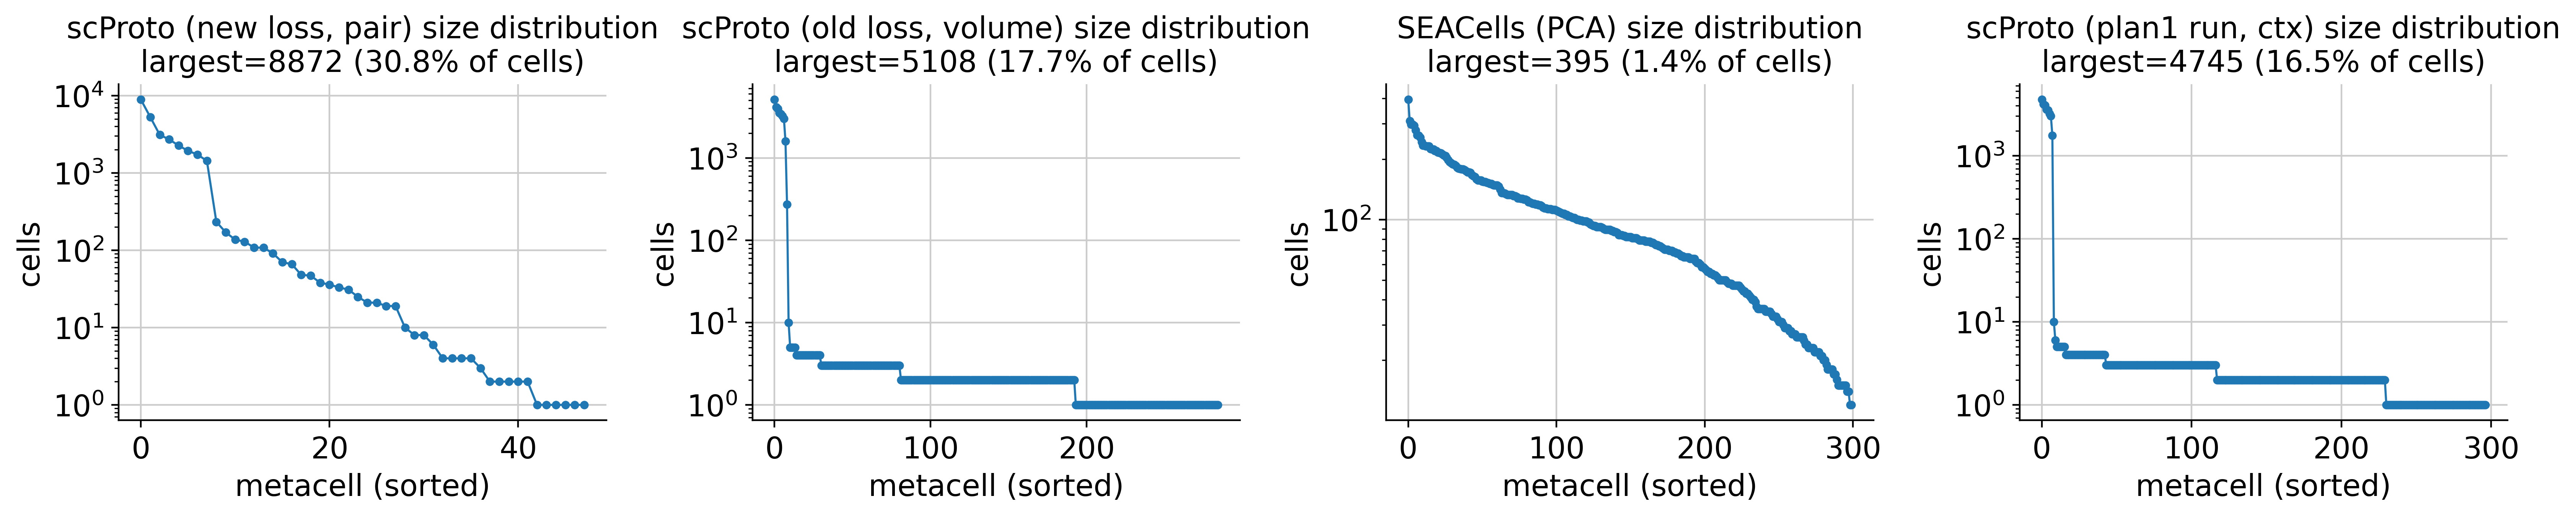

In [ ]:
# One panel per arm: metacell sizes, sorted, log y.
# A CLIFF (a few giants, then a drop to near-empty) is the collapse signature;
# a smooth PLATEAU is healthy.
fig, axes = plt.subplots(1, len(labels), figsize=(4.2 * len(labels), 3.6))
for ax, (n, lab) in zip(np.atleast_1d(axes), labels.items()):
    cd.plot_collapse(lab, name=n, axes=[ax])
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, f'{DS_ID}_collapse.png'), bbox_inches='tight', dpi=200)
plt.show()

## 5. Ground truth — niche-vs-rest DE on real single cells

Wilcoxon rank-sum within each cell type, niche X vs. all other niches, on the real single
cells. This is what every method is scored against, and it is method-independent — so it
is computed once and shared by every arm.

In [ ]:
ground_truth = nd.get_ground_truth(
    adata, GT_PATH, ct_key=CT_KEY, niche_key=NICHE_KEY, force=FORCE_RERUN,
)
print(f'{len(ground_truth)} (cell type, niche) pairs')

ground truth: loaded from /content/drive/MyDrive/codes/interpretable-prototype/files/celltype_niches_full.csv  (89 (cell type, niche) pairs)
89 (cell type, niche) pairs


## 6. DGE recovery per arm

Each arm writes its own CSV before the next one starts, so a disconnect loses at most one
arm. Re-running prints `loaded from ...` for the arms already done.

In [ ]:
results = {}
for name, lab in labels.items():
    results[name] = nd.run_niche_dge(
        name, lab, adata, ground_truth, TABLE_DIR,
        ct_key=CT_KEY, niche_key=NICHE_KEY, force=FORCE_RERUN,
    )
    gc.collect()

## 7. Compare

`pearson_r` / `kendall_tau` (branch 1, no significance gate) is the headline. `tpr`
(branch 2) is reported alongside and is expected lower — SuperCell's test was validated
on far more metacells per group than exist here. Every mean carries its std across cell
types.

In [ ]:
summary = nd.summary_table(results)
summary.to_csv(os.path.join(TABLE_DIR, 'dge_summary.csv'))
summary.round(3)

,pearson_r,kendall_tau,pearson_r_std,kendall_tau_std,tpr,tpr_std,n_pairs,n_metacells,median_mc_size
"scProto (new loss, pair)",0.311,0.216,0.295,0.167,0.865,0.182,8.0,48.0,23.0
"scProto (old loss, volume)",0.286,0.193,0.153,0.136,0.534,0.222,25.0,285.0,2.0
SEACells (PCA),0.756,0.518,0.099,0.093,0.955,0.011,17.0,300.0,82.0
"scProto (plan1 run, ctx)",0.291,0.205,0.258,0.197,0.545,0.192,25.0,297.0,2.0


In [ ]:
fig = nd.plot_dge_summary(
    summary, highlight=NEW_LOSS,
    out_path=os.path.join(FIG_DIR, f'{DS_ID}_dge_summary.png'),
    title=f'Niche-program recovery, within cell type ({DS_ID})',
)
plt.show()

### Paired, per (cell type, niche)

`pearson_r_gap_<arm>` = that arm minus the new-loss arm. Negative gap = the new loss wins
on that pair. Sorted so the new loss's worst pairs are at the top.

In [ ]:
paired = nd.compare_arms(results, reference=NEW_LOSS, metric='pearson_r')
gap_cols = [c for c in paired.columns if c.startswith('pearson_r_gap_')]
if gap_cols:
    paired = paired.sort_values(gap_cols[0], ascending=False)
paired.to_csv(os.path.join(TABLE_DIR, 'dge_paired.csv'), index=False)
paired.round(3).head(25)

### Size-floor sweep — is a remaining gap a size artifact or missing signal?

Restricts the comparison to pairs where the new-loss arm's own niche-positive metacells
clear a rising size floor. If its curve rises toward the baselines as the floor rises,
the residual gap is small-N pseudobulk noise, not absent signal. Flat at floor 30-50
means the signal genuinely is not there.

In [ ]:
sweep = nd.size_floor_sweep(results, size_arm=NEW_LOSS)
sweep.to_csv(os.path.join(TABLE_DIR, 'dge_size_floor_sweep.csv'), index=False)
print(sweep.round(3).to_string(index=False))

In [ ]:
fig = nd.plot_size_floor_sweep(
    sweep, arms=list(results), highlight=NEW_LOSS,
    out_path=os.path.join(FIG_DIR, f'{DS_ID}_size_floor_sweep.png'),
)
plt.show()

## 8. R4 — the non-circular discovery check

Everything above measures **recovery**: does a metacell reproduce a difference already
visible in the single cells? That is a validity check, not a discovery claim.

This section asks the question the paper actually needs: which niche programs are
**invisible to standard pooled cell-type DE** (all cells of a type, niche ignored) but
visible at the niche level? Those are the programs the paper claims existing analysis
averages away — and the pairs listed here, ranked by how well the new-loss arm recovers
them, are the candidates for the R4 figure.

Optional and last: nothing above depends on it.

In [ ]:
pooled = nd.pooled_celltype_de(adata, CT_KEY, path=POOLED_PATH, force=FORCE_RERUN)

candidates = nd.discovery_candidates(ground_truth, pooled, results, arm=NEW_LOSS)
candidates.to_csv(os.path.join(TABLE_DIR, 'discovery_candidates.csv'), index=False)
print(f'{len(candidates)} (cell type, niche) pairs have genes hidden from pooled DE')
candidates.head(15)

pooled cell-type DE: computing ...
pooled cell-type DE: saved to /content/drive/MyDrive/codes/interpretable-prototype/files/celltype_pooled_de.csv
30 (cell type, niche) pairs have genes hidden from pooled DE


,cell_type,niche,n_niche_genes,n_hidden_from_pooled,frac_hidden,"pearson_r_scProto (new loss, pair)",hidden_genes
0,Fibroblasts,Vascular stroma,34,1,0.029412,0.781709,GDF15
1,Fibroblasts,Tumor surface,90,3,0.033333,0.770604,"CD276, TPM2, VIM"
2,Fibroblasts,Desmoplastic stroma,56,1,0.017857,0.669317,VIM
3,Macrophages,Macrophage islands,90,10,0.111111,0.456720,"CD9, MMP19, INHBA, RGCC, ANXA2, CSF1, CD63, G6..."
4,Tumor cells,Tumor core,100,5,0.050000,0.383577,"IGKC, CALD1, FOS, FCGR3A, CD68"
5,Tumor cells,Tumor surface,97,1,0.010309,0.122280,CALD1
6,Cytotoxic T cells,Desmoplastic stroma,32,3,0.093750,0.078543,"CXCL10, IGHG1, MT2A"
7,Macrophages,Desmoplastic stroma,100,8,0.080000,-0.109075,"CD9, TAP1, ANXA2, IGF2R, CSF1, ITGA5, MX1, ICAM1"
8,Cytotoxic T cells,T cell aggregates,34,8,0.235294,NaN,"CXCL10, LAMP3, STAT1, DUSP5, PTGDS, MALAT1, MT..."
9,Regulatory T cells,Desmoplastic stroma,18,8,0.444444,NaN,"C1QB, PTGES3, HLA.DQA1, PTGDS, HLA.DRB5, HLA.D..."


## What to read off this notebook

1. **`collapse_summary.csv`** — did `dip_p` rise above 0.05 and `largest_share` fall
   under the new loss? That is the prerequisite. If not, stop here and fix the loss.
2. **`dge_summary.csv`** — did the new loss close the gap to SEACells on `pearson_r`?
3. **`dge_size_floor_sweep.csv`** — if a gap remains, is it a metacell-size artifact?
4. **`discovery_candidates.csv`** — which (cell type, niche) pairs carry programs that
   pooled DE cannot see. This is the shortlist the R4 figure gets built from.

Interpretation of these numbers is a separate conversation — this notebook produces
them, it does not decide what they mean.

In [ ]:
del adata
gc.collect()
torch.cuda.empty_cache()